# Player bounding

Load 20 frames from a SportsMOT training sequence for player-detection work.

In [2]:
from io import BytesIO
from pathlib import Path
import tarfile

from PIL import Image

archive_candidates = [
    Path(r"C:\Users\Dishi\OneDrive - University of Florida\UF!!!!\NvidaXBasketball\DSI-NVIDIA-Basketball-Shot-Analysis-Project\sportsmot_download\dataset\train.tar"),
    Path(r"C:\Users\Dishi\OneDrive - University of Florida\UF!!!!\NvidaXBasketball\DSI-NVIDIA-Basketball-Shot-Analysis-Project\sportsmot_download\dataset\train.tar"),
]
archive = next((path for path in archive_candidates if path.exists()), None)

if archive is None:
    raise FileNotFoundError("Could not find data/sportsmot_download/dataset/train.tar")

sequence = "train/v_-6Os86HzwCs_c001"

with tarfile.open(archive, "r") as tar:
    selected = sorted(
        (member for member in tar.getmembers()
         if member.isfile()
         and member.name.startswith(sequence + "/img1/")
         and member.name.endswith(".jpg")
         and not member.name.rsplit("/", 1)[-1].startswith("._")),
        key=lambda member: member.name,
    )[:20]

    images = [
        Image.open(BytesIO(tar.extractfile(member).read())).convert("RGB")
        for member in selected
    ]

print(f"Loaded {len(images)} frames from {sequence}")
print(f"First frame: {selected[0].name}")

Loaded 20 frames from train/v_-6Os86HzwCs_c001
First frame: train/v_-6Os86HzwCs_c001/img1/000001.jpg


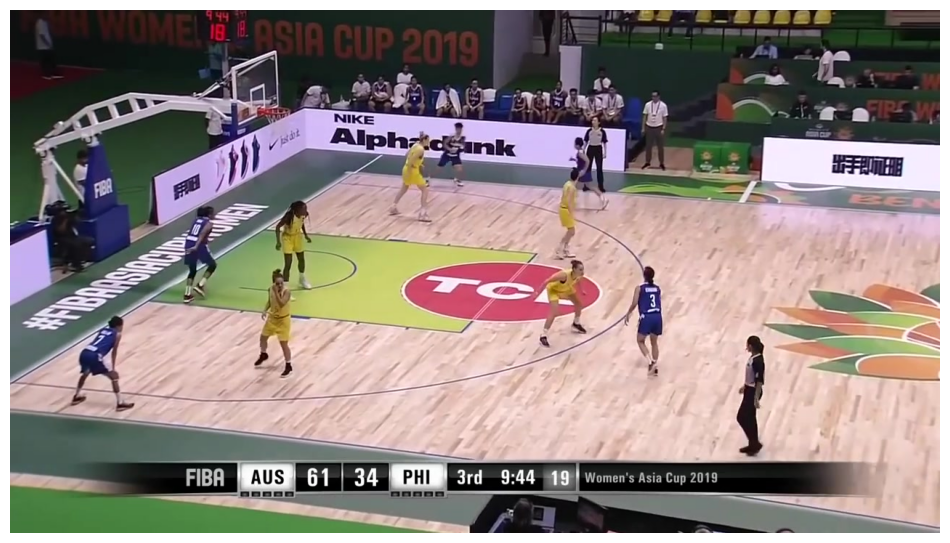

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))
plt.imshow(images[0])
plt.axis("off")
plt.show()

work here

In [4]:
from ultralytics import YOLO
print("it works")

it works



0: 736x1280 11 persons, 979.5ms
Speed: 28.0ms preprocess, 979.5ms inference, 35.0ms postprocess per image at shape (1, 3, 736, 1280)


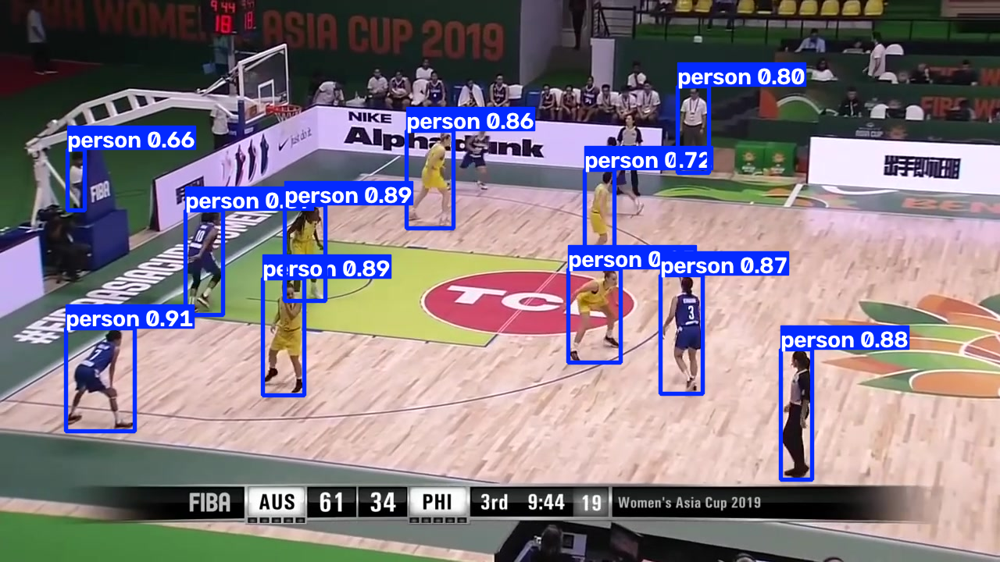

In [5]:
import numpy as np
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

with tarfile.open(archive, "r") as tar:
    names = sorted(m.name for m in tar.getmembers()
                   if m.name.startswith(sequence + "/img1/")
                   and m.name.endswith(".jpg")
                   and "/._" not in m.name)
    data = tar.extractfile(names[0]).read()

img = np.array(Image.open(BytesIO(data)).convert("RGB"))[..., ::-1]

results = model(img, classes=[0], conf=0.65, imgsz=1280) 
Image.fromarray(results[0].plot()[..., ::-1])

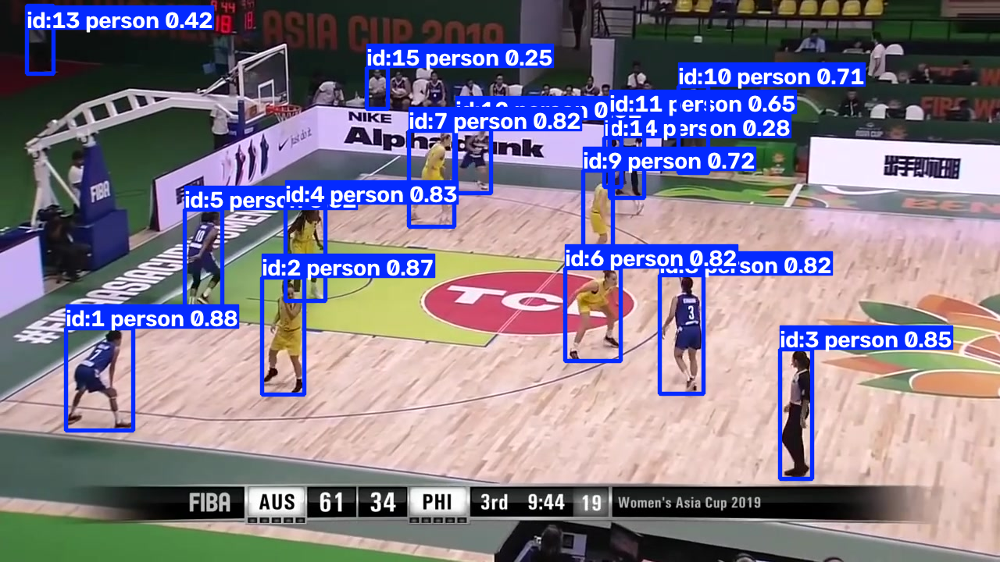

In [6]:
import numpy as np
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

with tarfile.open(archive, "r") as tar:
    names = sorted(m.name for m in tar.getmembers()
                   if m.name.startswith(sequence + "/img1/")
                   and m.name.endswith(".jpg")
                   and "/._" not in m.name)
    frames = [np.array(Image.open(BytesIO(tar.extractfile(n).read())).convert("RGB"))[..., ::-1]
              for n in names[:20]]

annotated = []
for frame in frames:
    r = model.track(frame, classes=[0], persist=True, tracker="bytetrack.yaml", verbose=False)[0]
    annotated.append(Image.fromarray(r.plot()[..., ::-1]))

annotated[0]

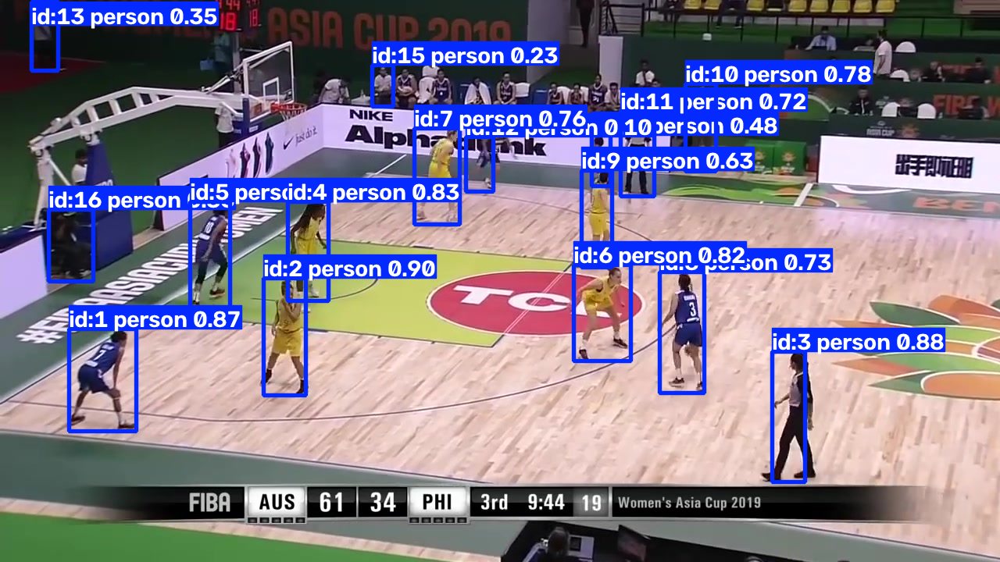

In [7]:
annotated[3]

I tried to create  a border around the court and tracked the people within that border. However, it is still detecting the referees. 

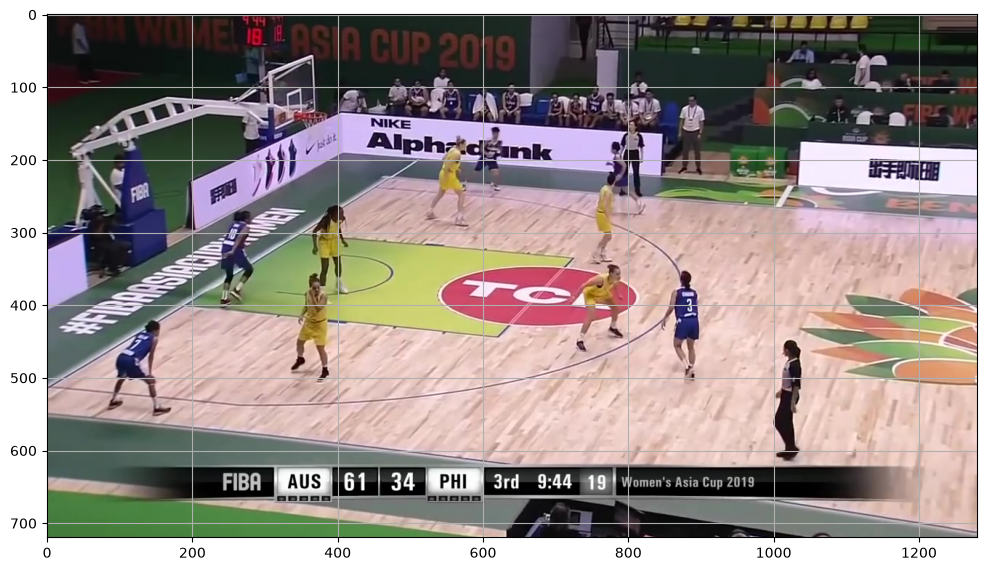

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))
plt.imshow(frames[0][..., ::-1])
plt.grid(True)
plt.show()

In [11]:
import cv2

court = np.array([[0, 570], [1280, 650], [1280, 235], [1000, 238],
                  [640, 208], [430, 185], [200, 295], [0, 470]], dtype=np.int32)

def on_court(box):
    x1, y1, x2, y2 = box
    feet = (float((x1 + x2) / 2), float(y2))
    return cv2.pointPolygonTest(court, feet, False) >= 0

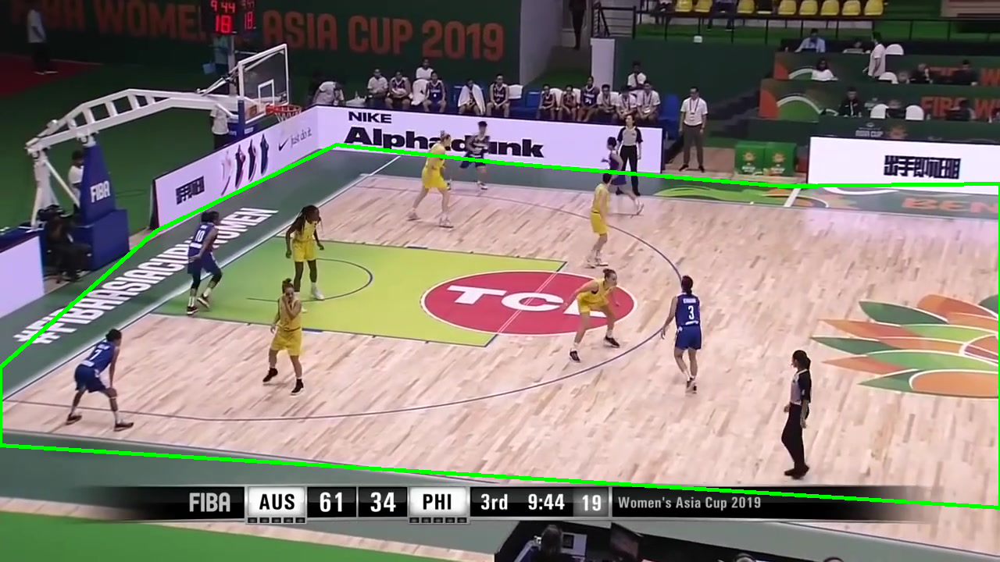

In [12]:
check = frames[0].copy()
cv2.polylines(check, [court], True, (0, 255, 0), 3)
Image.fromarray(check[..., ::-1])

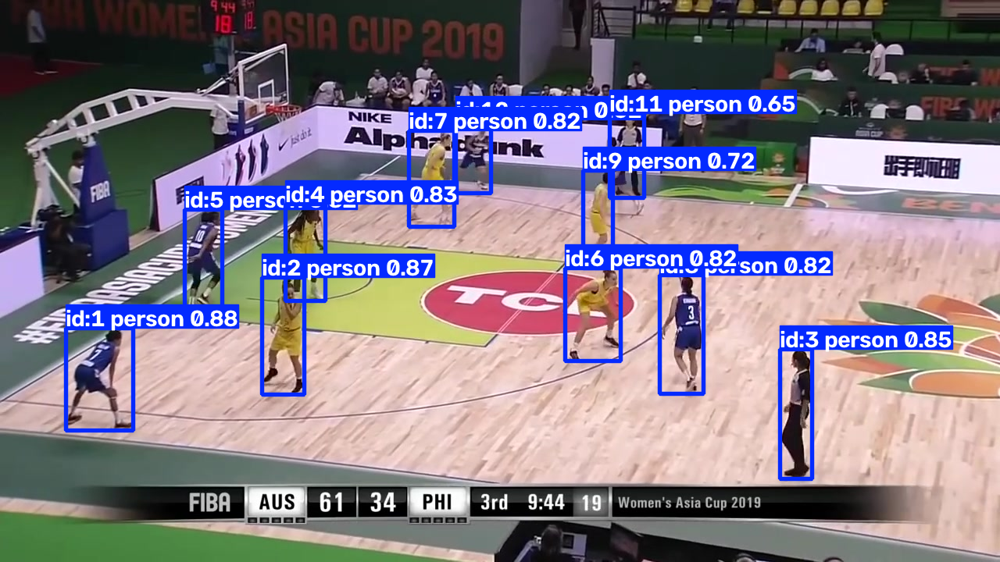

In [15]:
model = YOLO("yolov8m.pt")

annotated = []
for frame in frames:
    r = model.track(frame, classes=[0], conf=0.3, persist=True,
                    tracker="bytetrack.yaml", verbose=False)[0]
    keep = np.array([on_court(b) for b in r.boxes.xyxy.cpu().numpy()], dtype=bool)
    r = r[keep]
    annotated.append(Image.fromarray(r.plot()[..., ::-1]))

annotated[0]

In [14]:
r = model.predict(frames[0], classes=[0], conf=0.25, verbose=False)[0]
for b in r.boxes.xyxy.cpu().numpy():
    print(b.round(), on_court(b))

[         85         420         171         551] True
[        336         355         390         505] True
[        999         447        1039         614] True
[        366         261         417         386] True
[        237         269         285         403] True
[        724         343         795         463] True
[        523         168         581         291] True
[        844         352         900         504] True
[        746         218         785         343] True
[        868         111         906         221] False
[        781         146         824         254] True
[        583         153         628         247] True
[         34           7          68          94] False
[        773         176         796         240] True
[        469          87         497         139] False


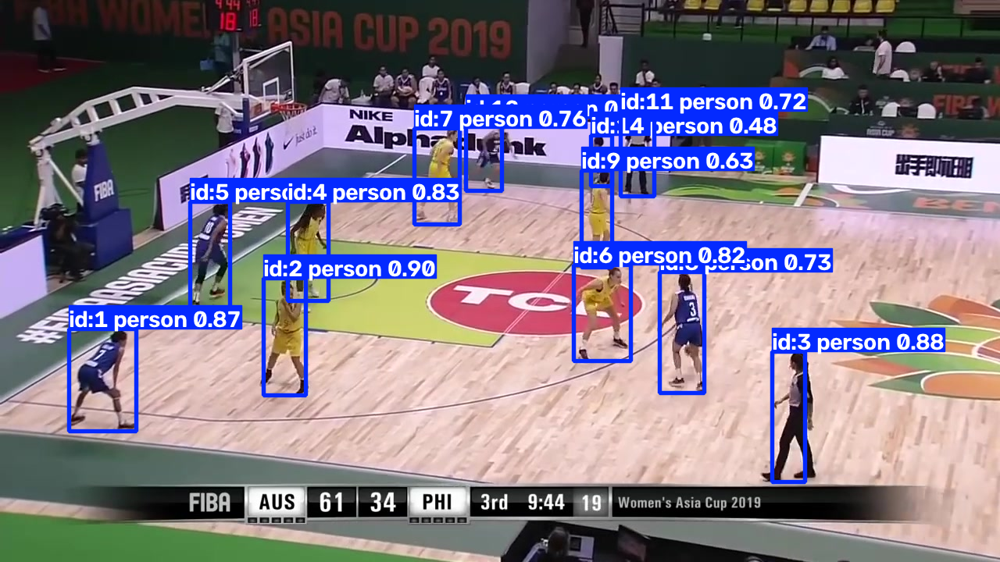

In [16]:
annotated[3]